In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/fraudTrain.csv")

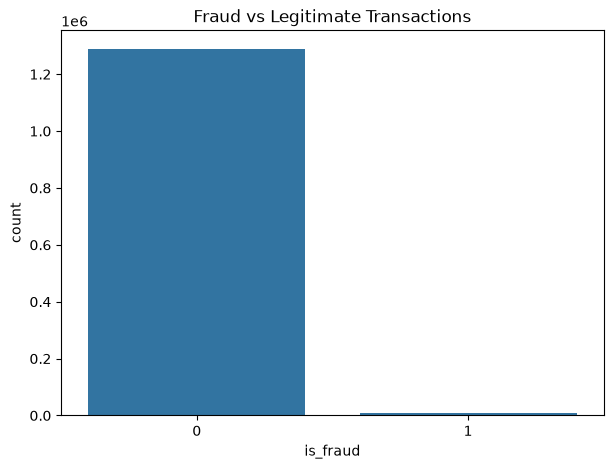

In [3]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="is_fraud")
plt.title("Fraud vs Legitimate Transactions")
plt.show()

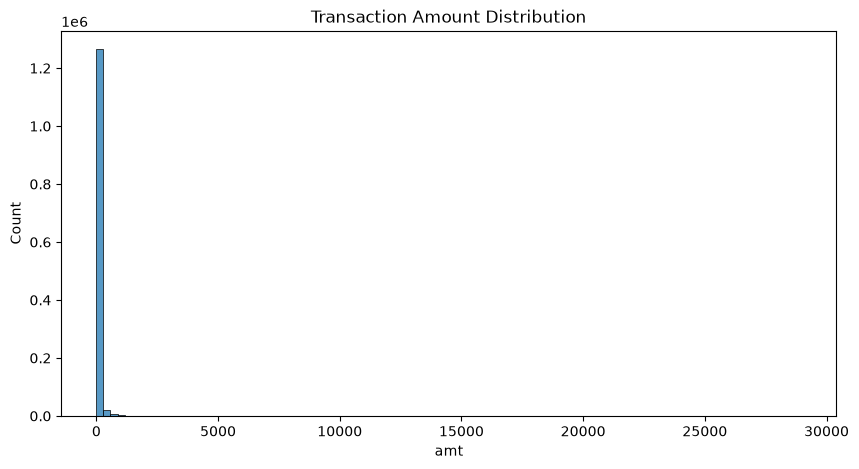

In [4]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x="amt", bins=100)
plt.title("Transaction Amount Distribution")
plt.show()

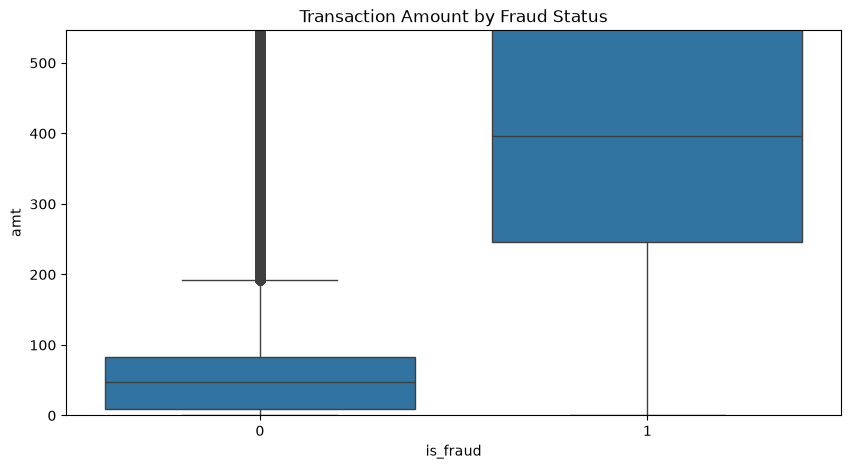

In [5]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x="is_fraud", y="amt")
plt.ylim(0, df["amt"].quantile(0.99))
plt.title("Transaction Amount by Fraud Status")
plt.show()

In [6]:
category_fraud = pd.crosstab(
    df["category"],
    df["is_fraud"],
    normalize="index"
) * 100

category_fraud

is_fraud,0,1
category,,
entertainment,99.752165,0.247835
food_dining,99.834902,0.165098
gas_transport,99.530606,0.469394
grocery_net,99.705183,0.294817
grocery_pos,98.590239,1.409761
health_fitness,99.845131,0.154869
home,99.839175,0.160825
kids_pets,99.788561,0.211439
misc_net,98.554205,1.445795


In [7]:
category_fraud = pd.crosstab(
    df["category"],
    df["is_fraud"],
    normalize="index"
) * 100

category_fraud

is_fraud,0,1
category,,
entertainment,99.752165,0.247835
food_dining,99.834902,0.165098
gas_transport,99.530606,0.469394
grocery_net,99.705183,0.294817
grocery_pos,98.590239,1.409761
health_fitness,99.845131,0.154869
home,99.839175,0.160825
kids_pets,99.788561,0.211439
misc_net,98.554205,1.445795


In [8]:
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])

In [9]:
df["hour"] = df["trans_date_trans_time"].dt.hour

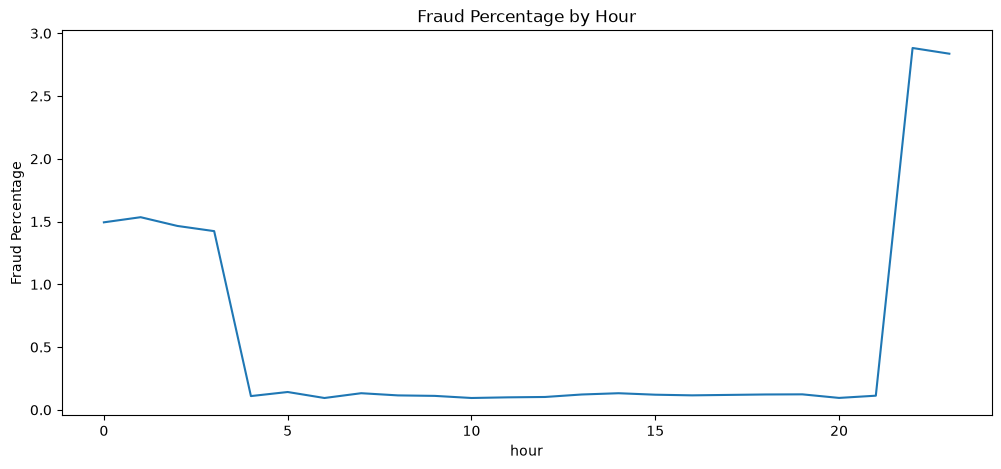

In [10]:
hour_fraud = df.groupby("hour")["is_fraud"].mean() * 100

plt.figure(figsize=(12,5))
hour_fraud.plot()
plt.title("Fraud Percentage by Hour")
plt.ylabel("Fraud Percentage")
plt.show()

In [11]:
df["day_of_week"] = df["trans_date_trans_time"].dt.dayofweek

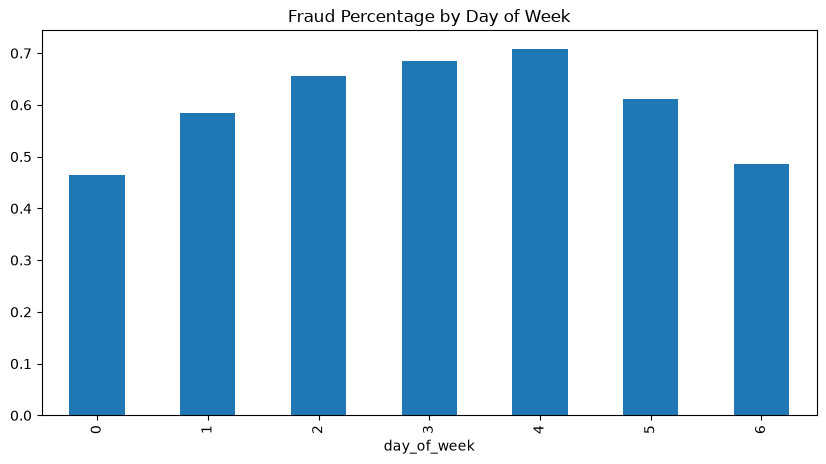

In [12]:
day_fraud = df.groupby("day_of_week")["is_fraud"].mean() * 100

plt.figure(figsize=(10,5))
day_fraud.plot(kind="bar")
plt.title("Fraud Percentage by Day of Week")
plt.show()

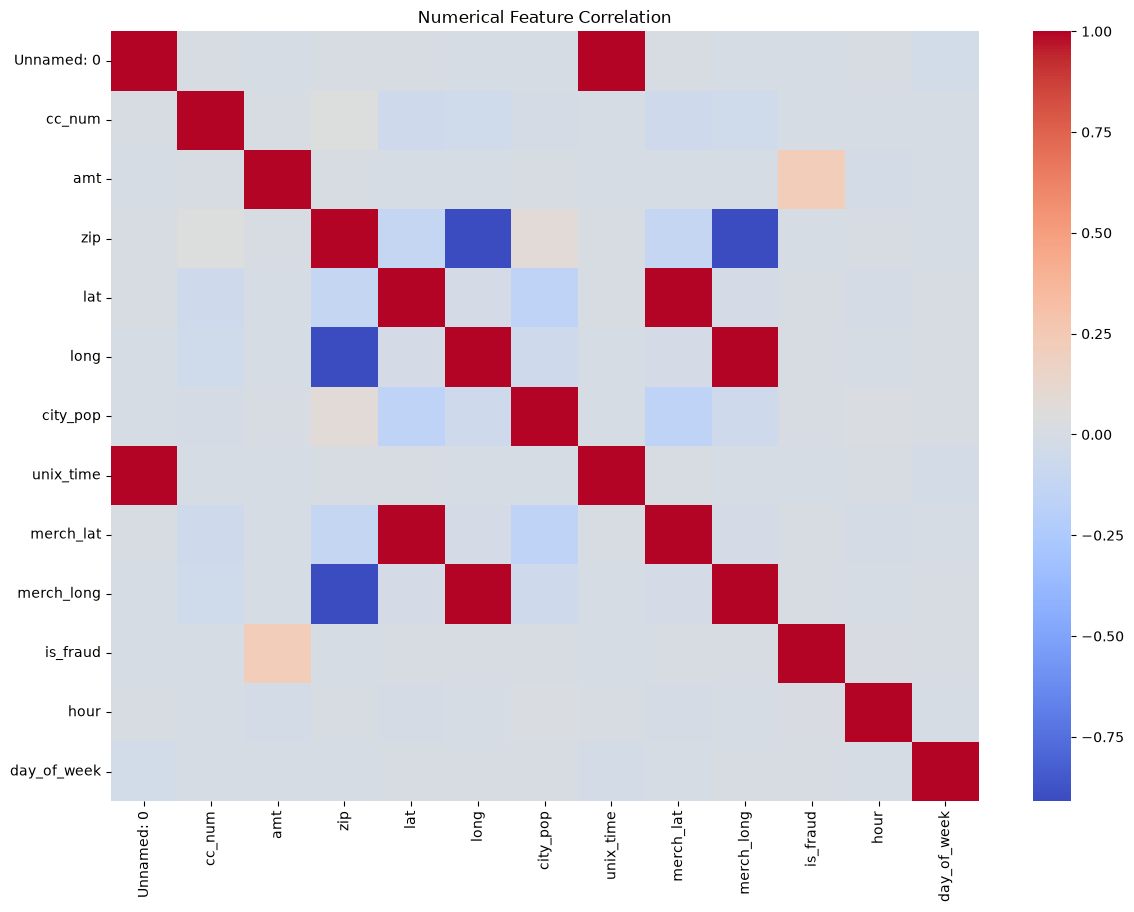

In [13]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14,10))
sns.heatmap(numeric_df.corr(), cmap="coolwarm")
plt.title("Numerical Feature Correlation")
plt.show()

In [14]:
df.groupby("is_fraud")["amt"].agg(["count", "mean", "median", "std", "min", "max"])

,count,mean,median,std,min,max
is_fraud,,,,,,
0,1289169,67.667110,47.280,154.007971,1.00,28948.90
1,7506,531.320092,396.505,390.560070,1.06,1376.04


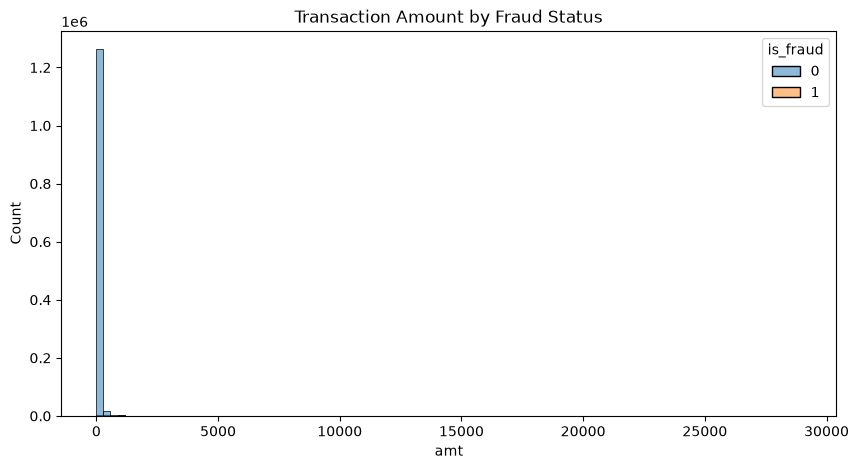

In [15]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x="amt", hue="is_fraud", bins=100)
plt.title("Transaction Amount by Fraud Status")
plt.savefig("../assets/transaction_amount_fraud.png")
plt.show()